# Laboratorio 9 — Embeddings

**Natural Language Processing**

En este laboratorio se construyen y comparan embeddings de palabras en español:

- **Corpus principal:** Spanish News Classification (`df_total.csv`), para entrenar embeddings y clasificar noticias.
- **Segundo corpus:** *Don Quijote de la Mancha* (`don-quijote.txt`), para comparar cómo cambia el significado según el texto.
- **Vectores preentrenados:** fastText SUC (tamaño M, 100 dimensiones).

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gensim
import sklearn
import torch

# Semilla para que los resultados sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Versiones (se usan para el requirements.txt)
print("gensim", gensim.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)

gensim 4.4.0
scikit-learn 1.8.0
torch 2.14.1


# 1. Preparación de los corpus

### 1.1 Carga de los datos

Cargamos las noticias y el Quijote. Del Quijote quitamos el texto de Project Gutenberg y dejamos solo la novela.

In [ ]:
# Corpus de noticias
df_news = pd.read_csv("df_total.csv")
print("Noticias:", df_news.shape)
print(df_news["Type"].value_counts())

# Corpus del Quijote (utf-8-sig quita el BOM del inicio del archivo)
with open("don-quijote.txt", encoding="utf-8-sig") as f:
    raw_quijote = f.read()

# Nos quedamos solo con la novela: desde el título hasta el aviso final de Gutenberg
inicio = raw_quijote.index("El ingenioso hidalgo don Quijote de la Mancha")
fin = raw_quijote.index("End of Project Gutenberg's Don Quijote")
quijote = raw_quijote[inicio:fin].strip()

print(f"\nQuijote: {len(quijote):,} caracteres")
print(quijote[:300])
print("...")
print(quijote[-200:])

### 1.2 Oraciones y tokens

Separamos cada corpus en oraciones y cada oración en palabras, en orden, porque gensim espera una lista de listas de tokens.

En las noticias falta el espacio después de muchos puntos (`agregó.El`), así que lo agregamos antes de separar las oraciones.

In [5]:
import re
import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt_tab", quiet=True)

TOKEN_RE = re.compile(r"\w+")


def segmentar(texto):
    """Divide un texto en oraciones."""
    # Agrega el espacio que falta después de . ! ? cuando sigue una mayúscula (p. ej. "agregó.El")
    texto = re.sub(r"(?<=\w)([.!?])(?=[A-ZÁÉÍÓÚÑ¿¡])", r"\1 ", texto)
    # Une los saltos de línea para no partir oraciones
    texto = re.sub(r"\s+", " ", texto)
    return sent_tokenize(texto, language="spanish")


def tokenizar(oracion):
    """Devuelve los tokens de una oración en orden (sin puntuación)."""
    return TOKEN_RE.findall(oracion)


# Noticias: cada noticia se segmenta por separado
oraciones_news = []
for texto in df_news["news"]:
    for oracion in segmentar(texto):
        tokens = tokenizar(oracion)
        if tokens:  # descarta "oraciones" que eran solo puntuación
            oraciones_news.append(tokens)

# Quijote
oraciones_quijote = [tokenizar(o) for o in segmentar(quijote)]
oraciones_quijote = [t for t in oraciones_quijote if t]

print(f"Noticias: {len(oraciones_news):,} oraciones")
print(f"Quijote:  {len(oraciones_quijote):,} oraciones")
print("\nEjemplo noticias:", oraciones_news[0])
print("Ejemplo Quijote: ", oraciones_quijote[100])

Noticias: 21,805 oraciones
Quijote:  9,513 oraciones

Ejemplo noticias: ['Durante', 'el', 'foro', 'La', 'banca', 'articulador', 'empresarial', 'para', 'el', 'desarrollo', 'sostenible', 'el', 'director', 'de', 'sostenibilidad', 'y', 'clientes', 'globales', 'de', 'BBVA', 'en', 'Colombia', 'Andrés', 'García', 'aseguró', 'que', 'es', 'importante', 'entender', 'que', 'la', 'sostenibilidad', 'no', 'la', 'podemos', 'asociar', 'a', 'mayores', 'costos']
Ejemplo Quijote:  ['No', 'puedo', 'ser', 'tu', 'igual', 'que', 'este', 'decoro', 'se', 'debe', 'a', 'tus', 'proezas', 'y', 'a', 'tu', 'fama', 'puesto', 'que', 'como', 'yo', 'perdiste', 'el', 'seso']


### 1.3 Vocabulario de fastText SUC

Revisamos si SUC distingue mayúsculas y tildes, para normalizar nuestros corpus de la misma forma.

In [6]:
from gensim.models import KeyedVectors

# El archivo pesa 1.1 GB: se guarda fuera del repositorio y no se sube a GitHub
SUC_PATH = "/Users/michelle/Downloads/embeddings-m-model.vec"
suc = KeyedVectors.load_word2vec_format(SUC_PATH, limit=200_000)
print("Vocabulario cargado:", len(suc.key_to_index))

for palabra in ["España", "españa", "espana", "Gobierno", "gobierno", "economía", "economia", "2020", "BBVA", "bbva"]:
    print(f"{palabra:<10}", palabra in suc.key_to_index)

Vocabulario cargado: 200000
España     False
españa     True
espana     True
Gobierno   False
gobierno   True
economía   True
economia   True
2020       True
BBVA       False
bbva       True


### 1.4 Normalización

Según la celda anterior, SUC está en minúsculas, distingue tildes y conserva los números. Normalizamos igual:

- **Minúsculas:** "Gobierno" y "gobierno" son la misma palabra.
- **Tildes:** se conservan, porque cambian el significado ("sé" / "se", "más" / "mas").
- **Números:** se conservan, como en SUC.
- **Puntuación:** ya se quitó al tokenizar.
- **Stopwords y lematización:** no se aplican. Quitar stopwords cambia qué palabras quedan juntas en la ventana de contexto, y lematizar junta "gobiernos" y "gobernó" en una sola forma, perdiendo información de número y tiempo verbal.

In [8]:
def normalizar(tokens):
    """Pasa los tokens a minúsculas."""
    return [t.lower() for t in tokens]


corpus_news = [normalizar(o) for o in oraciones_news]
corpus_quijote = [normalizar(o) for o in oraciones_quijote]

print("Antes:  ", oraciones_news[0][:12])
print("Después:", corpus_news[0][:12])

Antes:   ['Durante', 'el', 'foro', 'La', 'banca', 'articulador', 'empresarial', 'para', 'el', 'desarrollo', 'sostenible', 'el']
Después: ['durante', 'el', 'foro', 'la', 'banca', 'articulador', 'empresarial', 'para', 'el', 'desarrollo', 'sostenible', 'el']


### 1.5 Tamaño de los corpus

En las noticias cada noticia es un documento; en el Quijote, cada capítulo.

In [9]:
def resumen(nombre, n_docs, corpus):
    tokens = [t for oracion in corpus for t in oracion]
    return {"Corpus": nombre, "Documentos": n_docs, "Oraciones": len(corpus),
            "Tokens": len(tokens), "Tipos": len(set(tokens))}


n_capitulos = len(re.findall(r"^Capítulo ", quijote, flags=re.MULTILINE))

tabla_corpus = pd.DataFrame([
    resumen("Noticias", len(df_news), corpus_news),
    resumen("Quijote", n_capitulos, corpus_quijote),
])
tabla_corpus

,Corpus,Documentos,Oraciones,Tokens,Tipos
0,Noticias,1217,21805,637564,29530
1,Quijote,126,9513,381226,22942


### 1.6 Vocabulario según la frecuencia mínima

Solo entran al vocabulario las palabras que aparecen al menos `min_count` veces. Los tokens de las demás quedan fuera.

In [11]:
from collections import Counter

filas = []
for nombre, corpus in [("Noticias", corpus_news), ("Quijote", corpus_quijote)]:
    frecuencias = Counter(t for oracion in corpus for t in oracion)
    total_tokens = sum(frecuencias.values())
    for min_count in [1, 2, 5]:
        vocab = {w for w, c in frecuencias.items() if c >= min_count}
        tokens_fuera = sum(c for w, c in frecuencias.items() if c < min_count)
        filas.append({"Corpus": nombre, "min_count": min_count,
                      "Tamaño del vocabulario": len(vocab),
                      "% tokens fuera": round(100 * tokens_fuera / total_tokens, 2)})

pd.DataFrame(filas)

,Corpus,min_count,Tamaño del vocabulario,% tokens fuera
0,Noticias,1,29530,0.00
1,Noticias,2,17138,1.94
2,Noticias,5,8892,5.39
3,Quijote,1,22942,0.00
4,Quijote,2,11760,2.93
5,Quijote,5,5301,7.38


Con `min_count=2` el vocabulario de noticias baja 42% y solo pierde el 1.9% de los tokens: la mayoría de palabras son muy raras pero suman pocos tokens. Por eso el modelo base usa `min_count=2`.

### 1.7 Pares de skip-gram a mano

Para cada palabra central, sus contextos son las palabras que están hasta 2 posiciones a la izquierda y a la derecha.

In [12]:
def pares_skipgram(oracion, ventana=2):
    pares = []
    for i, centro in enumerate(oracion):
        for j in range(max(0, i - ventana), min(len(oracion), i + ventana + 1)):
            if j != i:
                pares.append((centro, oracion[j]))
    return pares


# Una oración corta de noticias para que se vean todos los pares
oracion_ejemplo = next(o for o in corpus_news if 6 <= len(o) <= 8)
print("Oración:", oracion_ejemplo)

pares = pares_skipgram(oracion_ejemplo, ventana=2)
print(f"\n{len(pares)} pares (palabra central, contexto):")
for centro, contexto in pares:
    print(f"  ({centro}, {contexto})")

Oración: ['viva', 'aerobus', 'es', 'como', 'un', 'hijo', 'para', 'mí']

26 pares (palabra central, contexto):
  (viva, aerobus)
  (viva, es)
  (aerobus, viva)
  (aerobus, es)
  (aerobus, como)
  (es, viva)
  (es, aerobus)
  (es, como)
  (es, un)
  (como, aerobus)
  (como, es)
  (como, un)
  (como, hijo)
  (un, es)
  (un, como)
  (un, hijo)
  (un, para)
  (hijo, como)
  (hijo, un)
  (hijo, para)
  (hijo, mí)
  (para, un)
  (para, hijo)
  (para, mí)
  (mí, hijo)
  (mí, para)


### 1.8 Pares de entrenamiento en todo el corpus de noticias

In [13]:
def contar_pares(corpus, ventana):
    """Cuenta los pares (centro, contexto) sin guardarlos en memoria."""
    total = 0
    for oracion in corpus:
        n = len(oracion)
        for i in range(n):
            total += min(i, ventana) + min(n - 1 - i, ventana)
    return total


n_tokens_news = sum(len(o) for o in corpus_news)
filas = []
for ventana in [2, 5]:
    n_pares = contar_pares(corpus_news, ventana)
    filas.append({"Ventana": ventana, "Tokens": n_tokens_news, "Pares": n_pares,
                  "Pares por token": round(n_pares / n_tokens_news, 2)})

pd.DataFrame(filas)

,Ventana,Tokens,Pares,Pares por token
0,2,637564,2419548,3.79
1,5,637564,5723708,8.98


**¿Por qué word2vec no necesita datos etiquetados?** Porque el propio texto genera las "etiquetas": para cada palabra, la respuesta correcta son las palabras que la rodean. Con solo ~640 mil tokens se obtienen millones de ejemplos de entrenamiento sin que nadie anote nada (aprendizaje auto-supervisado).

# 2. Co-ocurrencia, PPMI y SVD

### 2.1 Matriz de co-ocurrencia

Contamos cuántas veces aparece cada par de palabras a ±2 posiciones, usando las 2,000 palabras más frecuentes de las noticias.

In [16]:
N_PALABRAS = 2000
VENTANA = 2

frecuencias_news = Counter(t for oracion in corpus_news for t in oracion)
vocab_cooc = [w for w, _ in frecuencias_news.most_common(N_PALABRAS)]
idx_cooc = {w: i for i, w in enumerate(vocab_cooc)}

C = np.zeros((N_PALABRAS, N_PALABRAS), dtype=np.float64)
for oracion in corpus_news:
    ids = [idx_cooc.get(t, -1) for t in oracion]
    for i, wi in enumerate(ids):
        if wi < 0:
            continue
        for j in range(max(0, i - VENTANA), min(len(ids), i + VENTANA + 1)):
            if j != i and ids[j] >= 0:
                C[wi, ids[j]] += 1

print("Forma:", C.shape)
print(f"Ceros: {100 * (C == 0).mean():.2f}%")

Forma: (2000, 2000)
Ceros: 93.70%


In [17]:
# Dispersión de la BoW reportada en el Laboratorio 2 (mismas noticias)
comparacion = pd.DataFrame([
    {"Matriz": "Co-ocurrencia (2,000 x 2,000)", "% ceros": round(100 * (C == 0).mean(), 2)},
    {"Matriz": "BoW Lab 2 - 1,000 palabras (1,217 x 1,000)", "% ceros": 89.03},
    {"Matriz": "BoW Lab 2 - 5,000 palabras (1,217 x 5,000)", "% ceros": 96.73},
    {"Matriz": "BoW Lab 2 - vocabulario completo (1,217 x 21,911)", "% ceros": 99.14},
])
comparacion

,Matriz,% ceros
0,"Co-ocurrencia (2,000 x 2,000)",93.70
1,"BoW Lab 2 - 1,000 palabras (1,217 x 1,000)",89.03
2,"BoW Lab 2 - 5,000 palabras (1,217 x 5,000)",96.73
3,"BoW Lab 2 - vocabulario completo (1,217 x 21,911)",99.14


La matriz de co-ocurrencia tiene 93.70% de ceros, entre la BoW de 1,000 y la de 5,000 palabras del Lab 2. Las dos son dispersas porque cada palabra (o documento) se relaciona solo con una parte pequeña del vocabulario. La co-ocurrencia es algo menos dispersa porque aquí conservamos las stopwords, que aparecen junto a casi todas las palabras.

### 2.2 Similitud coseno entre filas

Cada fila de la matriz describe una palabra por sus vecinas. Comparamos pares relacionados y no relacionados.

In [18]:
def coseno(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


pares_prueba = [
    ("empresa", "compañía"),     # relacionadas
    ("enero", "febrero"),        # relacionadas
    ("inflación", "precios"),    # relacionadas
    ("banco", "agua"),           # no relacionadas
    ("tecnología", "febrero"),   # no relacionadas
]

pd.DataFrame(
    [{"Palabra 1": a, "Palabra 2": b, "Coseno (conteos)": round(coseno(C[idx_cooc[a]], C[idx_cooc[b]]), 3)}
     for a, b in pares_prueba]
)

,Palabra 1,Palabra 2,Coseno (conteos)
0,empresa,compañía,0.960
1,enero,febrero,0.927
2,inflación,precios,0.492
3,banco,agua,0.766
4,tecnología,febrero,0.690


Coincide solo en parte con la intuición: empresa–compañía y enero–febrero salen muy altas, pero banco–agua (0.77) supera a inflación–precios (0.49). Con conteos crudos, dos palabras se parecen solo por compartir vecinas muy frecuentes como "de", "la" o "el".

### 2.3 Palabras que más co-ocurren con "empresa" y "gobierno"

In [19]:
def top_vecinas(matriz, palabra, k=10):
    fila = matriz[idx_cooc[palabra]]
    orden = np.argsort(fila)[::-1][:k]
    return [f"{vocab_cooc[j]} ({fila[j]:.0f})" for j in orden]


pd.DataFrame({p: top_vecinas(C, p) for p in ["empresa", "gobierno"]})

,empresa,gobierno
0,la (205),el (218)
1,de (152),del (108)
2,una (65),de (83)
3,en (48),que (65)
4,que (47),y (56)
5,y (39),nacional (36)
6,a (32),en (30)
7,con (28),por (24)
8,para (19),al (24)
9,como (17),para (24)


Dominan las stopwords ("la", "de", "el", "que"): son tan frecuentes que aparecen junto a cualquier palabra, así que los conteos crudos no dicen mucho del significado.

### 2.4 PPMI

PPMI compara cuántas veces aparecen juntas dos palabras contra cuántas veces se esperaría si fueran independientes:

$$PPMI(w, c) = \max\left(0, \log_2 \frac{P(w, c)}{P(w) \cdot P(c)}\right)$$

In [20]:
total = C.sum()
P_wc = C / total                  # P(w, c)
P_w = C.sum(axis=1) / total       # P(w)
P_c = C.sum(axis=0) / total       # P(c)

with np.errstate(divide="ignore"):  # log2(0) = -inf cuando el par nunca aparece
    pmi = np.log2(P_wc / np.outer(P_w, P_c))
PPMI = np.maximum(pmi, 0)           # los -inf y los valores negativos quedan en 0

print("Forma:", PPMI.shape)
print(f"Ceros: {100 * (PPMI == 0).mean():.2f}%")

pd.DataFrame({
    p: [f"{vocab_cooc[j]} ({PPMI[idx_cooc[p], j]:.2f})" for j in np.argsort(PPMI[idx_cooc[p]])[::-1][:10]]
    for p in ["empresa", "gobierno"]
})

Forma: (2000, 2000)
Ceros: 94.93%


,empresa,gobierno
0,telecomunicaciones (5.47),corporativo (7.25)
1,líder (5.16),federal (5.84)
2,llega (5.10),sánchez (5.42)
3,especializada (5.03),nacional (5.32)
4,cualquier (4.85),iván (5.22)
5,estadounidense (4.67),funcionarios (5.21)
6,colombiana (4.58),estará (4.85)
7,asegurar (4.56),petro (4.84)
8,criterios (4.46),duque (4.46)
9,española (4.26),pueda (4.43)


Con PPMI desaparecen las stopwords: para "gobierno" salen "federal", "nacional", "funcionarios" y presidentes (Sánchez, Duque, Petro), y para "empresa" "telecomunicaciones", "líder" y nacionalidades. Cambió porque PPMI premia las palabras que aparecen juntas **más de lo esperado por azar**, y las stopwords aparecen con todo. Su defecto es que pares poco frecuentes pueden salir altos por casualidad ("llega", "pueda").

### 2.5 Reducción con SVD

Reducimos la matriz PPMI de 2,000 a 100 dimensiones con `TruncatedSVD`. Estos vectores densos (estilo LSA) son nuestro primer modelo de embeddings.

In [21]:
from sklearn.decomposition import TruncatedSVD
from gensim.models import KeyedVectors

svd = TruncatedSVD(n_components=100, random_state=SEED)
vectores_svd = svd.fit_transform(PPMI)
print("Forma:", vectores_svd.shape)
print(f"Varianza explicada: {100 * svd.explained_variance_ratio_.sum():.1f}%")

# Se guardan como KeyedVectors para compararlos en la sección 5
kv_svd = KeyedVectors(vector_size=100)
kv_svd.add_vectors(vocab_cooc, vectores_svd)

for palabra in ["empresa", "gobierno", "enero"]:
    print(palabra, "->", [w for w, _ in kv_svd.most_similar(palabra, topn=5)])

Forma: (2000, 100)
Varianza explicada: 25.2%
empresa -> ['plataforma', 'tecnología', 'compañía', 'asociación', 'marca']
gobierno -> ['congreso', 'república', 'banco', 'comisión', 'central']
enero -> ['septiembre', 'octubre', 'julio', 'diciembre', 'junio']


**¿Por qué las filas ya son vectores de palabras?** Cada fila describe una palabra por las palabras que la rodean; según la hipótesis distribucional, palabras con contextos parecidos tienen significados parecidos, así que sus filas también se parecen.

**¿Qué resuelven PPMI y SVD?** PPMI quita el peso de las palabras muy frecuentes (stopwords) y resalta las asociaciones informativas. SVD reduce 2,000 dimensiones dispersas a 100 densas: ocupa menos memoria y junta contextos parecidos, así que dos palabras pueden parecerse aunque no compartan exactamente las mismas vecinas.

# 4. Entrenar Word2Vec y fastText

### 4.1 Modelo base

Word2Vec skip-gram sobre las noticias con la configuración base del laboratorio. Usamos 6 palabras de control para comparar los modelos.

In [22]:
import time
from gensim.models import Word2Vec

CONFIG_BASE = dict(vector_size=100, window=5, min_count=2, sg=1, negative=5, epochs=10)
PALABRAS_CONTROL = ["banco", "gobierno", "empresa", "mercado", "tecnología", "sostenibilidad"]


def entrenar_w2v(corpus, **cambios):
    """Entrena Word2Vec con la configuración base más los cambios indicados."""
    config = {**CONFIG_BASE, **cambios}
    inicio = time.time()
    modelo = Word2Vec(corpus, seed=SEED, workers=1, **config)  # workers=1 para que sea reproducible
    return modelo, time.time() - inicio


def vecinos(kv, palabra, k=5):
    return ", ".join(w for w, _ in kv.most_similar(palabra, topn=k))


w2v_base, t_base = entrenar_w2v(corpus_news)
print(f"Vocabulario: {len(w2v_base.wv):,} palabras | Tiempo: {t_base:.1f} s")
print("Palabras de control fuera del vocabulario:", [p for p in PALABRAS_CONTROL if p not in w2v_base.wv])

pd.DataFrame({"Palabra": PALABRAS_CONTROL,
              "Vecinas (base)": [vecinos(w2v_base.wv, p) for p in PALABRAS_CONTROL]})

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulario: 17,138 palabras | Tiempo: 19.5 s
Palabras de control fuera del vocabulario: []


,Palabra,Vecinas (base)
0,banco,"central, república, agrario, popular, sudameris"
1,gobierno,"congreso, senado, asumir, mandatario, biden"
2,empresa,"startup, compañía, emergente, criptomoneda, pl..."
3,mercado,"sector, mercados, dificultan, apetito, regulador"
4,tecnología,"estandarización, innovación, aplicada, dedicad..."
5,sostenibilidad,"digitalización, alineado, diversidad, palancas..."


### 4.2 Variantes

Cambiamos un parámetro a la vez respecto al modelo base.

In [23]:
# Mostrar las listas de vecinas completas, sin "..."
pd.set_option("display.max_colwidth", None)

variantes = {
    "Base (sg=1, window=5, 100d)": {},
    "CBOW (sg=0)": dict(sg=0),
    "Ventana 2": dict(window=2),
    "Ventana 10": dict(window=10),
    "Dimensión 50": dict(vector_size=50),
    "Dimensión 300": dict(vector_size=300),
}

modelos_w2v = {"Base (sg=1, window=5, 100d)": w2v_base}
tiempos = {"Base (sg=1, window=5, 100d)": t_base}
for nombre, cambios in variantes.items():
    if nombre not in modelos_w2v:
        modelos_w2v[nombre], tiempos[nombre] = entrenar_w2v(corpus_news, **cambios)
        print(f"{nombre}: {tiempos[nombre]:.1f} s")

tabla_variantes = pd.DataFrame([
    {"Variante": nombre, "Tiempo (s)": round(tiempos[nombre], 1),
     **{p: vecinos(m.wv, p) for p in PALABRAS_CONTROL}}
    for nombre, m in modelos_w2v.items()
])
tabla_variantes

CBOW (sg=0): 5.3 s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Ventana 2: 10.3 s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Ventana 10: 27.9 s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Dimensión 50: 13.1 s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Dimensión 300: 36.5 s


,Variante,Tiempo (s),banco,gobierno,empresa,mercado,tecnología,sostenibilidad
0,"Base (sg=1, window=5, 100d)",19.5,"central, república, agrario, popular, sudameris","congreso, senado, asumir, mandatario, biden","startup, compañía, emergente, criptomoneda, plataforma","sector, mercados, dificultan, apetito, regulador","estandarización, innovación, aplicada, dedicada, controlados","digitalización, alineado, diversidad, palancas, empoderamiento"
1,CBOW (sg=0),5.3,"cordillera, grupo, equipo, finalizaría, área","congreso, estado, consejo, coronavirus, regulador","startup, marca, plataforma, compañía, dirección","país, sector, mundo, territorio, desempeño","digitalización, experiencia, sociedad, tecnológica, transformación","innovación, digitalización, transformación, descarbonización, empresarial"
2,Ventana 2,10.3,"central, bce, gnb, sudameris, cordillera","congreso, bce, federal, reserva, consejo","startup, plataforma, compañía, jurisdicción, matriz","sector, financiamiento, conglomerado, regulador, plano","capacitación, internet, publicidad, nfc, educativa","digitalización, creatividad, equidad, excelencia, internacionalización"
3,Ventana 10,27.9,"central, agrario, popular, república, bancos","congreso, disyuntiva, creg, ordena, maduro","compañía, startup, emergente, biotecnología, plataforma","colombiano, accionario, sector, sólido, sumada","estandarización, neurálgico, gokoan, biológicos, autentificación","monográficos, alineado, prioridades, suscríbete, ballabriga"
4,Dimensión 50,13.1,"central, república, popular, agrario, referencia","congreso, asumir, regulador, senado, estímulo","compañía, startup, plataforma, emergente, liga","apetito, desempeño, creciente, ganando, jugador","estandarización, premisa, innovación, blockchain, controlados","digitalización, sociedad, diversidad, empoderamiento, biodiversidad"
5,Dimensión 300,36.5,"central, república, popular, agrario, sudameris","congreso, asumir, biden, senado, estímulo","startup, emergente, criptomoneda, compañía, publicitaria","sector, mercados, colombiano, dificultan, apetito","estandarización, controlados, dedicada, cuántica, computación","digitalización, empoderamiento, alineado, misión, palancas"


**¿Ventanas pequeñas = vecinos sintácticos, grandes = temáticos?** En parte. Con ventana 2 las vecinas son palabras que pueden **sustituir** a la palabra en la misma posición: banco → bce, gnb, sudameris (otros bancos); gobierno → bce, federal, reserva, consejo (otras instituciones). Con ventana 10 aparecen palabras del mismo **tema** pero también más ruido (gobierno → disyuntiva, creg, maduro; sostenibilidad → suscríbete, monográficos), porque una ventana grande mezcla todo lo que hay en la oración y el corpus es pequeño.

CBOW da vecinas más generales y frecuentes (mercado → país, mundo; banco → grupo, equipo), porque promedia el contexto. Cambiar la dimensión (50 o 300) casi no cambia las vecinas. CBOW es el más rápido (5 s) y dimensión 300 el más lento (37 s).

### 4.3 Noticias vs Quijote

Entrenamos la misma configuración sobre el Quijote y comparamos 5 palabras que aparecen en ambos corpus. Cambiamos "caballo", "señor" y "palabra" porque no aparecen (o casi no aparecen) en las noticias.

In [24]:
w2v_quijote, t_quijote = entrenar_w2v(corpus_quijote)
print(f"Vocabulario Quijote: {len(w2v_quijote.wv):,} palabras | Tiempo: {t_quijote:.1f} s")

palabras_comunes = ["dinero", "casa", "mundo", "gobierno", "historia"]
pd.DataFrame({
    "Palabra": palabras_comunes,
    "Vecinas (noticias)": [vecinos(w2v_base.wv, p) for p in palabras_comunes],
    "Vecinas (Quijote)": [vecinos(w2v_quijote.wv, p) for p in palabras_comunes],
})

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulario Quijote: 11,760 palabras | Tiempo: 9.9 s


,Palabra,Vecinas (noticias),Vecinas (Quijote)
0,dinero,"vivir, exacto, fácilmente, estorbo, permitía","dueño, señalando, rogarle, hacéis, haréis"
1,casa,"pasiva, filtro, potabilidad, remoto, reformar","aldea, compañía, hija, majestad, presente"
2,mundo,"vira, intentan, territorio, salto, acelerando","orbe, infierno, iguala, desear, habido"
3,gobierno,"congreso, senado, asumir, mandatario, biden","escrúpulo, pago, perdón, precio, condado"
4,historia,"especialidad, bandera, palabra, época, roja","autor, cide, hamete, benengeli, impresa"


Las mismas palabras cambian de sentido según el corpus: "historia" en el Quijote queda junto a Cide Hamete Benengeli (el narrador ficticio), y "gobierno" junto a condado y precio (el gobierno de la ínsula prometido a Sancho), mientras que en las noticias "gobierno" está junto a congreso y senado. Esto confirma que **el significado viene del corpus**: el modelo solo aprende los contextos que ve.

### 4.4 fastText y palabras fuera del vocabulario

fastText arma el vector de una palabra con sus n-gramas de caracteres, así que puede dar un vector incluso a palabras que nunca vio. Probamos un error de dedo, una conjugación poco común y una palabra inventada.

In [25]:
from gensim.models import FastText

inicio = time.time()
ft_news = FastText(corpus_news, seed=SEED, workers=1, **CONFIG_BASE)
print(f"fastText entrenado en {time.time() - inicio:.1f} s\n")

palabras_oov = ["gobeirno", "invirtiéramos", "criptoempresa"]  # error de dedo, conjugación rara, inventada

for palabra in palabras_oov:
    print(f"{palabra}  (¿en el vocabulario? {palabra in ft_news.wv.key_to_index})")
    print("  fastText ->", vecinos(ft_news.wv, palabra))
    try:
        print("  Word2Vec ->", vecinos(w2v_base.wv, palabra))
    except KeyError as error:
        print("  Word2Vec -> KeyError:", error)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


fastText entrenado en 38.5 s

gobeirno  (¿en el vocabulario? False)
  fastText -> cuaderno, gobierno, planetario, dañino, lejano
  Word2Vec -> KeyError: "Key 'gobeirno' not present in vocabulary"
invirtiéramos  (¿en el vocabulario? False)
  fastText -> invitamos, aspiramos, enamoramos, miramos, imaginamos
  Word2Vec -> KeyError: "Key 'invirtiéramos' not present in vocabulary"
criptoempresa  (¿en el vocabulario? False)
  fastText -> empresa, criptomoneda, criptografía, cripto, impresora
  Word2Vec -> KeyError: "Key 'criptoempresa' not present in vocabulary"


fastText da vector a las tres palabras porque las arma con sus n-gramas: "criptoempresa" queda junto a empresa y criptomoneda, y "gobeirno" junto a gobierno. Pero se guía por la forma más que por el significado: "gobeirno" también queda junto a "cuaderno" (comparten "-erno") e "invirtiéramos" junto a otras palabras en "-amos". Word2Vec da `KeyError` porque solo tiene vectores para las palabras que vio al entrenar.

### 4.5 Elección del mejor modelo

Comparamos las vecinas del Word2Vec base y de fastText en las palabras de control.

In [26]:
pd.DataFrame({
    "Palabra": PALABRAS_CONTROL,
    "Word2Vec base": [vecinos(w2v_base.wv, p) for p in PALABRAS_CONTROL],
    "fastText": [vecinos(ft_news.wv, p) for p in PALABRAS_CONTROL],
})

,Palabra,Word2Vec base,fastText
0,banco,"central, república, agrario, popular, sudameris","mibanco, bancoomeva, bancoldex, bancos, banrep"
1,gobierno,"congreso, senado, asumir, mandatario, biden","gobiernos, niinisto, invierno, congreso, precandidato"
2,empresa,"startup, compañía, emergente, criptomoneda, plataforma","empresarial, empresario, empresariado, empresas, presa"
3,mercado,"sector, mercados, dificultan, apetito, regulador","mercadoni, supermercado, acercado, mercadeo, mercadante"
4,tecnología,"estandarización, innovación, aplicada, dedicada, controlados","biotecnología, tecnologías, ideología, endocrinología, tecnológica"
5,sostenibilidad,"digitalización, alineado, diversidad, palancas, empoderamiento","sostenida, elegibilidad, tangibilidad, legibilidad, credibilidad"


**Mejor modelo: Word2Vec base** (skip-gram, ventana 5, 100 dimensiones). Sus vecinas tienen relación de significado (banco → central, república; gobierno → congreso, senado). fastText, en cambio, encuentra palabras que se escriben parecido pero no significan lo mismo (mercado → supermercado, gobierno → invierno, tecnología → ideología). Su ventaja con palabras nuevas no compensa esto para el resto del laboratorio. Entre las variantes de Word2Vec, ventana 10 y CBOW dieron vecinas más ruidosas o generales, y la dimensión casi no cambió nada, así que nos quedamos con la configuración base.

In [28]:
# Vectores del mejor modelo (entregable del laboratorio)
mejor_w2v = w2v_base
mejor_w2v.wv.save("w2v_noticias.kv")
print("Guardado: w2v_noticias.kv |", len(mejor_w2v.wv), "palabras x", mejor_w2v.wv.vector_size, "dimensiones")

Guardado: w2v_noticias.kv | 17138 palabras x 100 dimensiones


# 5. Similitud, vecinos y analogías

Comparamos cuatro modelos: SVD sobre PPMI, el mejor Word2Vec de noticias, el Word2Vec del Quijote y fastText SUC.

### 5.1 Similitud coseno y vecinos

Verificamos que nuestra función `coseno` (sección 2.2) da lo mismo que `similarity` de gensim.

In [29]:
modelos = {
    "SVD-PPMI": kv_svd,
    "W2V noticias": mejor_w2v.wv,
    "W2V Quijote": w2v_quijote.wv,
    "fastText SUC": suc,
}

pares_verificacion = [("empresa", "compañía"), ("gobierno", "congreso"), ("banco", "agua")]
pd.DataFrame([
    {"Par": f"{a} / {b}",
     "coseno propio": round(float(coseno(mejor_w2v.wv[a], mejor_w2v.wv[b])), 6),
     "gensim similarity": round(float(mejor_w2v.wv.similarity(a, b)), 6)}
    for a, b in pares_verificacion
])

,Par,coseno propio,gensim similarity
0,empresa / compañía,0.670884,0.670884
1,gobierno / congreso,0.721032,0.721032
2,banco / agua,0.083946,0.083946


In [30]:
palabras_5 = ["gobierno", "dinero", "empresa", "guerra", "trabajo"]


def vecinos_o_vacio(kv, palabra, k=5):
    return vecinos(kv, palabra, k) if palabra in kv.key_to_index else "(fuera del vocabulario)"


pd.DataFrame([
    {"Palabra": p, **{nombre: vecinos_o_vacio(kv, p) for nombre, kv in modelos.items()}}
    for p in palabras_5
])

,Palabra,SVD-PPMI,W2V noticias,W2V Quijote,fastText SUC
0,gobierno,"congreso, república, banco, comisión, central","congreso, senado, asumir, mandatario, biden","escrúpulo, pago, perdón, precio, condado","elgobierno, gobier, go­bierno, ministro, gobiernos"
1,dinero,"algún, efectivo, reservas, liquidez, momento","vivir, exacto, fácilmente, estorbo, permitía","dueño, señalando, rogarle, hacéis, haréis","dinerito, dineral, centavo, gastarlo, dinerillo"
2,empresa,"plataforma, tecnología, compañía, asociación, marca","startup, compañía, emergente, criptomoneda, plataforma","peligrosa, herida, novedad, rara, demanda","compañía, constructora, subsidiaria, comercializadora, aseguradora"
3,guerra,"invasión, crisis, rusia, pandemia, conflicto","ucrania, invasión, rusia, conflicto, contagios","común, escoger, valentía, iguala, miseria","guerras, guera, contienda, bélica, invasión"
4,trabajo,"profesional, esfuerzo, su, innovación, talento","remoto, teletrabajo, colaborativo, utilidad, articulado","recogimiento, daño, yerro, estimar, pierda","remunerado, empleo, tabajo, trabaio, detrabajo"


fastText SUC da las vecinas más limpias (empresa → constructora, subsidiaria, aseguradora), aunque también variantes y errores de escritura (gobier, tabajo) por su tamaño y sus n-gramas. Los modelos de noticias reflejan la actualidad (guerra → ucrania, rusia; trabajo → teletrabajo, remoto) y el del Quijote su época (empresa como "hazaña": peligrosa, herida, novedad).

**Antónimos**

In [31]:
antonimos = [("bueno", "malo"), ("subir", "bajar"), ("ganar", "perder"), ("público", "privado")]


def similitud_o_nan(kv, a, b):
    if a in kv.key_to_index and b in kv.key_to_index:
        return round(float(kv.similarity(a, b)), 3)
    return np.nan  # alguna palabra fuera del vocabulario


pd.DataFrame([
    {"Par": f"{a} / {b}", **{nombre: similitud_o_nan(kv, a, b) for nombre, kv in modelos.items()}}
    for a, b in antonimos
])

,Par,SVD-PPMI,W2V noticias,W2V Quijote,fastText SUC
0,bueno / malo,NaN,0.769,0.813,0.717
1,subir / bajar,NaN,0.762,0.771,0.937
2,ganar / perder,NaN,0.675,0.745,0.689
3,público / privado,0.546,0.682,NaN,0.653


Las similitudes de los antónimos son **altas** (0.65 a 0.94; subir/bajar llega a 0.94 en SUC). Los antónimos aparecen en los mismos contextos ("el resultado fue bueno / malo", "los precios van a subir / bajar"), y los embeddings solo miden eso: qué tan intercambiables son dos palabras en el texto. Por eso **similitud distribucional no es sinonimia**: el modelo sabe que las dos palabras hablan de lo mismo, pero no si significan lo mismo o lo contrario. (En SVD faltan varias palabras porque solo tiene 2,000; en el Quijote faltan "público" y "privado".)

### 5.2 Conjunto de similitud propio

20 pares con un puntaje de 0 (sin relación) a 10 (casi sinónimos), y su correlación de Spearman con el coseno de cada modelo.

In [32]:
from scipy.stats import spearmanr

gold = [
    ("empresa", "compañía", 9.5), ("presidente", "mandatario", 9.0), ("trabajo", "empleo", 9.0),
    ("país", "nación", 9.0), ("caída", "descenso", 9.0), ("guerra", "conflicto", 8.5),
    ("dinero", "efectivo", 8.0), ("crecimiento", "aumento", 8.0), ("enero", "febrero", 7.0),
    ("gobierno", "estado", 7.0), ("inversión", "capital", 7.0), ("tecnología", "innovación", 6.5),
    ("banco", "crédito", 6.0), ("sostenibilidad", "ambiente", 6.0), ("mercado", "precios", 5.0),
    ("ciudad", "capital", 5.0), ("empresa", "café", 1.0), ("guerra", "tecnología", 1.0),
    ("banco", "agua", 0.5), ("mes", "presidente", 0.5),
]

filas = []
for nombre, kv in modelos.items():
    humanos, cosenos = [], []
    for a, b, puntaje in gold:
        if a in kv.key_to_index and b in kv.key_to_index:
            humanos.append(puntaje)
            cosenos.append(kv.similarity(a, b))
    rho, _ = spearmanr(humanos, cosenos)
    filas.append({"Modelo": nombre, "Spearman": round(rho, 3), "Pares evaluados": len(humanos),
                  "Pares fuera del vocabulario": len(gold) - len(humanos)})

pd.DataFrame(filas)

,Modelo,Spearman,Pares evaluados,Pares fuera del vocabulario
0,SVD-PPMI,0.510,17,3
1,W2V noticias,0.707,20,0
2,W2V Quijote,-0.200,4,16
3,fastText SUC,0.510,20,0


El modelo que más se parece a nuestro juicio es el **Word2Vec de noticias** (Spearman 0.71), por encima de fastText SUC (0.51) aunque SUC se entrenó con mucho más texto: los 20 pares son de economía y noticias, el mismo dominio de nuestro modelo. El Quijote solo cubre 4 de los 20 pares (le faltan palabras modernas como tecnología o inversión), así que su correlación no es confiable. Con solo 20 pares, las diferencias entre modelos deben tomarse con cuidado.

### 5.3 Analogías

"a es a b como c es a ?" se resuelve con el vector b − a + c: normalizamos los vectores, buscamos los más cercanos por coseno y excluimos a, b y c.

In [33]:
def analogia(kv, a, b, c, k=5, excluir=True):
    """Resuelve a : b :: c : ? con el vector b - a + c."""
    vectores = kv.get_normed_vectors()  # todos los vectores con norma 1
    consulta = vectores[kv.key_to_index[b]] - vectores[kv.key_to_index[a]] + vectores[kv.key_to_index[c]]
    consulta = consulta / np.linalg.norm(consulta)
    similitudes = vectores @ consulta  # coseno contra todo el vocabulario
    resultado = []
    for i in np.argsort(similitudes)[::-1]:
        palabra = kv.index_to_key[i]
        if excluir and palabra in (a, b, c):
            continue
        resultado.append(palabra)
        if len(resultado) == k:
            break
    return resultado


# Verificación contra gensim con fastText SUC
for a, b, c in [("hombre", "rey", "mujer"), ("españa", "madrid", "francia"), ("comer", "comía", "hablar")]:
    propio = analogia(suc, a, b, c)
    gensim_ = [w for w, _ in suc.most_similar(positive=[b, c], negative=[a], topn=5)]
    print(f"{a} : {b} :: {c} : ?")
    print("  propia:", propio)
    print("  gensim:", gensim_, "| ¿iguales?", propio == gensim_)

hombre : rey :: mujer : ?
  propia: ['reina', 'princesa', 'consorte', 'sibila', 'isabel']
  gensim: ['reina', 'princesa', 'consorte', 'sibila', 'isabel'] | ¿iguales? True
españa : madrid :: francia : ?
  propia: ['toulouse', 'parís', 'lille', 'montpellier', 'rennes']
  gensim: ['toulouse', 'parís', 'lille', 'montpellier', 'rennes'] | ¿iguales? True
comer : comía :: hablar : ?
  propia: ['hablaba', 'escuchaba', 'hablara', 'conversaba', 'hablé']
  gensim: ['hablaba', 'escuchaba', 'hablara', 'conversaba', 'hablé'] | ¿iguales? True


**18 analogías propias de 6 tipos** (a : b :: c : respuesta). Para cada modelo guardamos el top 5 y la posición de la respuesta correcta dentro del top 10.

In [34]:
analogias_propias = {
    "Género": [("hombre", "rey", "mujer", "reina"), ("padre", "madre", "hermano", "hermana"),
               ("señor", "señora", "niño", "niña")],
    "País-capital": [("españa", "madrid", "francia", "parís"), ("colombia", "bogotá", "perú", "lima"),
                     ("alemania", "berlín", "italia", "roma")],
    "País-gentilicio": [("colombia", "colombiano", "méxico", "mexicano"), ("españa", "español", "chile", "chileno"),
                        ("francia", "francés", "alemania", "alemán")],
    "Singular-plural": [("empresa", "empresas", "banco", "bancos"), ("país", "países", "ciudad", "ciudades"),
                        ("mercado", "mercados", "precio", "precios")],
    "Tiempos verbales": [("comía", "comerá", "hablaba", "hablará"), ("compra", "compró", "vende", "vendió"),
                         ("crece", "creció", "baja", "bajó")],
    "Adjetivos masc-fem": [("bueno", "buena", "nuevo", "nueva"), ("alto", "alta", "pequeño", "pequeña"),
                           ("económico", "económica", "político", "política")],
}

filas = []
for nombre, kv in modelos.items():
    for tipo, lista in analogias_propias.items():
        for a, b, c, d in lista:
            if all(w in kv.key_to_index for w in (a, b, c, d)):
                top10 = analogia(kv, a, b, c, k=10)
                posicion = top10.index(d) + 1 if d in top10 else None
                top5 = ", ".join(top10[:5])
            else:
                posicion, top5 = None, "(fuera del vocabulario)"
            filas.append({"Modelo": nombre, "Tipo": tipo, "Analogía": f"{a} : {b} :: {c} : {d}",
                          "Vecinas (top 5)": top5, "Posición": posicion})

detalle_analogias = pd.DataFrame(filas)
detalle_analogias

,Modelo,Tipo,Analogía,Vecinas (top 5),Posición
0,SVD-PPMI,Género,hombre : rey :: mujer : reina,(fuera del vocabulario),NaN
1,SVD-PPMI,Género,padre : madre :: hermano : hermana,(fuera del vocabulario),NaN
2,SVD-PPMI,Género,señor : señora :: niño : niña,(fuera del vocabulario),NaN
3,SVD-PPMI,País-capital,españa : madrid :: francia : parís,(fuera del vocabulario),NaN
4,SVD-PPMI,País-capital,colombia : bogotá :: perú : lima,(fuera del vocabulario),NaN
...,...,...,...,...,...
67,fastText SUC,Tiempos verbales,compra : compró :: vende : vendió,"vendió, robó, vendía, vendieron, regaló",1.0
68,fastText SUC,Tiempos verbales,crece : creció :: baja : bajó,"decreció, alta, bajó, disminuyó, aumentó",3.0
69,fastText SUC,Adjetivos masc-fem,bueno : buena :: nuevo : nueva,"nueva, unanueva, renovada, futura, gran",1.0
70,fastText SUC,Adjetivos masc-fem,alto : alta :: pequeño : pequeña,"pequeña, diminuto, pequeñísimo, grande, diminuta",1.0


In [35]:
# Porcentaje de aciertos en top 1 y top 5 por tipo y modelo
detalle_analogias["Top 1"] = detalle_analogias["Posición"] == 1
detalle_analogias["Top 5"] = detalle_analogias["Posición"] <= 5

resumen_analogias = (detalle_analogias
                     .groupby(["Tipo", "Modelo"])[["Top 1", "Top 5"]].mean().mul(100).round(0)
                     .unstack("Modelo"))
resumen_analogias

Top 1                                          Top 5  \
Modelo             SVD-PPMI W2V Quijote W2V noticias fastText SUC SVD-PPMI   
Tipo                                                                         
Adjetivos masc-fem      0.0         0.0          0.0        100.0      0.0   
Género                  0.0         0.0          0.0        100.0      0.0   
País-capital            0.0         0.0          0.0          0.0      0.0   
País-gentilicio         0.0         0.0         33.0        100.0      0.0   
Singular-plural        33.0         0.0          0.0        100.0     33.0   
Tiempos verbales        0.0         0.0          0.0         67.0      0.0   

                                                          
Modelo             W2V Quijote W2V noticias fastText SUC  
Tipo                                                      
Adjetivos masc-fem         0.0          0.0        100.0  
Género                     0.0          0.0        100.0  
País-capital               0.0          0.0        100.0  
País-gentilicio            0.0         67.0        100.0  
Singular-plural            0.0         67.0        100.0  
Tiempos verbales           0.0          0.0        100.0

fastText SUC resuelve casi todo: 100% en top 5 en los seis tipos, aunque en país–capital la respuesta nunca queda en primer lugar (españa : madrid :: francia → toulouse antes que parís). Nuestro Word2Vec de noticias solo acierta algunos gentilicios y plurales, y el SVD y el Quijote fallan sobre todo porque la mayoría de las palabras no están en su vocabulario. Las analogías morfológicas (plural, femenino, tiempos) funcionan mejor que las semánticas (capitales, género), porque dependen de patrones muy regulares en el texto.

**Analogías sin excluir las palabras de la consulta**

In [36]:
cinco_analogias = [analogias_propias[t][0] for t in ["Género", "País-capital", "País-gentilicio",
                                                    "Singular-plural", "Adjetivos masc-fem"]]

pd.DataFrame([
    {"Analogía": f"{a} : {b} :: {c} : {d}",
     "Excluyendo a, b, c": ", ".join(analogia(suc, a, b, c, k=3)),
     "Sin excluir": ", ".join(analogia(suc, a, b, c, k=3, excluir=False))}
    for a, b, c, d in cinco_analogias
])

,Analogía,"Excluyendo a, b, c",Sin excluir
0,hombre : rey :: mujer : reina,"reina, princesa, consorte","reina, rey, princesa"
1,españa : madrid :: francia : parís,"toulouse, parís, lille","toulouse, parís, lille"
2,colombia : colombiano :: méxico : mexicano,"mexicano, michoacano, jalisco","mexicano, michoacano, jalisco"
3,empresa : empresas :: banco : bancos,"bancos, crediticias, microfinancieras","banco, bancos, crediticias"
4,bueno : buena :: nuevo : nueva,"nueva, unanueva, renovada","nueva, nuevo, unanueva"


Sin excluir, la respuesta sigue primero en 4 de 5 casos, pero las palabras de la consulta se meten en el top 3 (rey, nuevo) y en empresa : empresas :: banco gana "banco" (la palabra c) sobre "bancos". El vector b − a + c no cae exactamente sobre la respuesta: queda en una zona cercana a ella y a las palabras de la consulta. Por eso el "≈" de rey − hombre + mujer ≈ reina **no es una igualdad**: es "la palabra más cercana, sin contar las de la pregunta".

# 6. Visualización del espacio

Proyectamos unas 140 palabras de 6 grupos a 2 dimensiones con PCA y t-SNE, en nuestro mejor modelo y en fastText SUC.

Palabras a visualizar: 143
{'Países': 32, 'Economía': 28, 'Profesiones': 27, 'Movimiento': 25, 'Números': 19, 'Meses': 12}


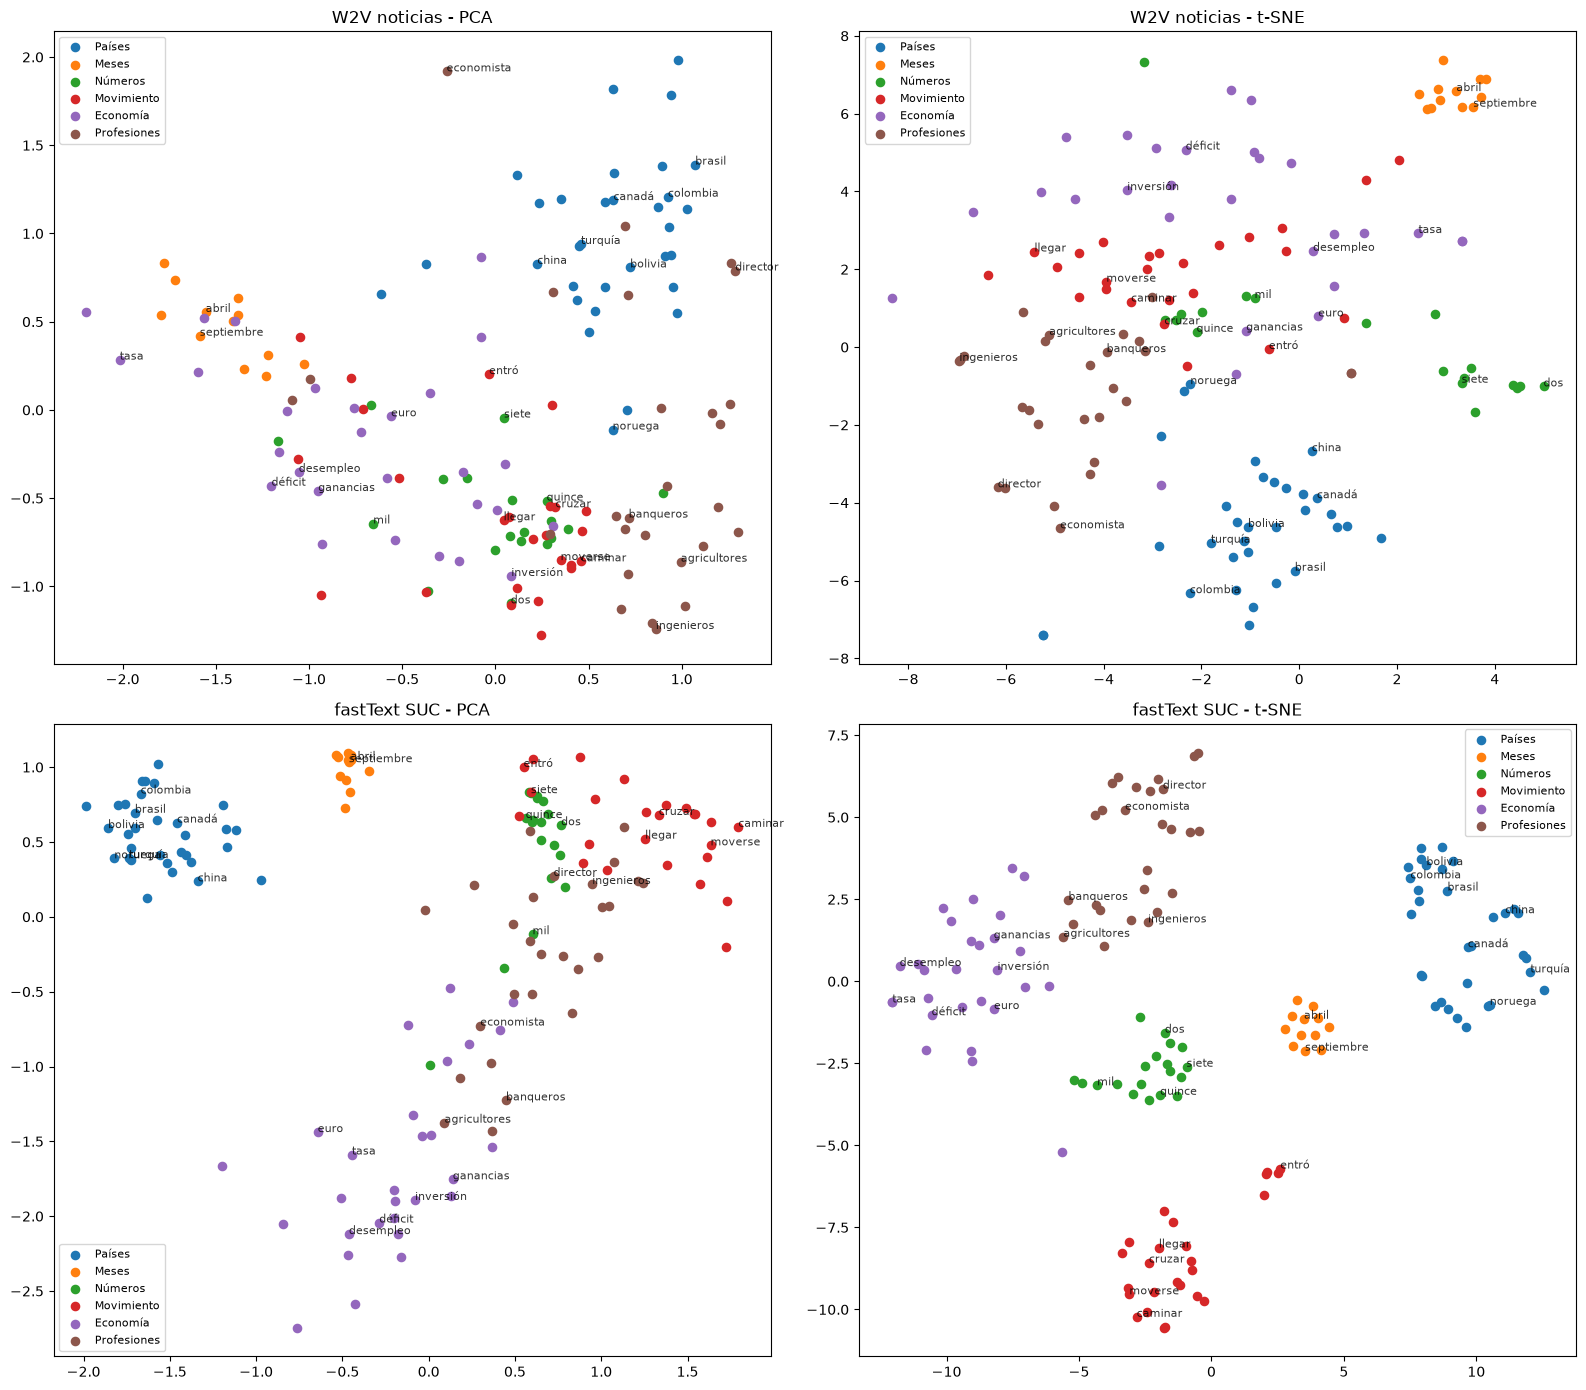

In [37]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

grupos = {
    "Países": "colombia méxico perú chile argentina brasil españa francia alemania italia china japón india rusia ucrania canadá ecuador venezuela uruguay paraguay bolivia panamá portugal corea israel turquía australia suiza bélgica suecia noruega irlanda",
    "Meses": "enero febrero marzo abril mayo junio julio agosto septiembre octubre noviembre diciembre",
    "Números": "uno dos tres cuatro cinco seis siete ocho nueve diez doce quince veinte treinta cincuenta cien mil millón millones",
    "Movimiento": "ir venir llegar salir entrar subir bajar caminar correr viajar volar mover moverse regresar volver avanzar retroceder cruzar trasladar transportar llegó salió entró avanzó volvió",
    "Economía": "inflación precios tasa tasas interés crédito deuda inversión mercado bolsa acciones dólar euro peso pib crecimiento recesión desempleo exportaciones importaciones impuestos presupuesto déficit banco divisas capital ingresos ganancias",
    "Profesiones": "médico médicos abogado ingeniero ingenieros profesor profesores maestro periodista economista economistas arquitecto científico científicos agricultores empresario empresarios ministro presidente director gerente analista analistas banquero banqueros consultor desarrolladores",
}

# Solo palabras presentes en los dos modelos
palabras_vis, grupo_vis = [], []
for grupo, texto in grupos.items():
    for w in texto.split():
        if w in mejor_w2v.wv.key_to_index and w in suc.key_to_index:
            palabras_vis.append(w)
            grupo_vis.append(grupo)
print("Palabras a visualizar:", len(palabras_vis))
print(pd.Series(grupo_vis).value_counts().to_dict())

colores = dict(zip(grupos, plt.cm.tab10.colors))
etiquetar = set(palabras_vis[::5])  # rotulamos 1 de cada 5 palabras para que se lea

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for fila, (nombre, kv) in enumerate([("W2V noticias", mejor_w2v.wv), ("fastText SUC", suc)]):
    X = np.array([kv[w] for w in palabras_vis])
    proyecciones = {
        "PCA": PCA(n_components=2, random_state=SEED).fit_transform(X),
        "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X),
    }
    for col, (metodo, P) in enumerate(proyecciones.items()):
        ax = axes[fila, col]
        for grupo in grupos:
            m = np.array(grupo_vis) == grupo
            ax.scatter(P[m, 0], P[m, 1], color=colores[grupo], label=grupo, s=35)
        for (x, y), w in zip(P, palabras_vis):
            if w in etiquetar:
                ax.annotate(w, (x, y), fontsize=8, alpha=0.8)
        ax.set_title(f"{nombre} - {metodo}")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**¿Se forman los grupos esperados?** Sí, sobre todo en fastText SUC con t-SNE, donde aparecen los seis grupos separados. Hay detalles con sentido: los verbos en pasado (entró, llegó) forman un subgrupo dentro de movimiento, y profesiones económicas (banqueros, agricultores) quedan pegadas a los términos económicos. En nuestro Word2Vec de noticias se separan bien meses, países y números, pero economía, profesiones y movimiento se mezclan: con menos datos el modelo distingue menos.

**¿En qué modelo se separan mejor?** En fastText SUC, por el tamaño de su corpus.

**PCA vs t-SNE.** PCA es una proyección lineal que conserva las direcciones de mayor varianza, así que muchos grupos quedan encimados. t-SNE busca que los puntos cercanos en el espacio original sigan cercanos en 2D, por eso separa mejor los grupos. Podemos confiar en los grupos (quién está junto a quién), pero no en la distancia entre grupos ni en su tamaño: t-SNE solo cuida a los vecinos cercanos y puede poner dos grupos lejos o cerca sin que eso refleje su distancia real.

# 7. Análisis

### Vecinos de "banco"

"banco" tiene un solo vector en cada modelo. Revisamos sus 10 vecinas para ver qué sentidos se mezclan.

In [38]:
pd.DataFrame({nombre: [w for w, _ in kv.most_similar("banco", topn=10)]
              for nombre, kv in modelos.items() if "banco" in kv.key_to_index})

,SVD-PPMI,W2V noticias,W2V Quijote,fastText SUC
0,bbva,central,roncos,hipotecario
1,grupo,república,desenvainó,bancos
2,central,agrario,túnica,bank
3,colombia,popular,palamenta,citibank
4,también,sudameris,bordón,monetario
5,país,gnb,tendidos,kfw
6,davivienda,coopcentral,marfil,bancaria
7,gobierno,caja,requiriendo,bancario
8,entidad,colpatria,merendaron,hsbc
9,mercado,finandina,inmundos,fmi
